# Beyond the Bell Curve: Extreme Movements in Gold and Oil Returns

In [ ]:
import pandas as pd
import numpy as np
import io
import os
from scipy import stats
from scipy.stats import norm
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


np.random.seed(42)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/DS603_Group_project/Crude_Gold_data.xlsx'
df = pd.read_excel(file_path)

display(df.head())

Mounted at /content/drive


,(dsmnemonic) DSMnemonic - Datastream mnemonic for a commodity,(date_) Date_ - Market date in YYYYMMDD format. Date on which t,(comcode) ComCode - Commodity Code. This is an automatically ge,(close_) Close_ - Closing value of a commodity for the given da
0,GOLDBLN,2000-01-04,1865,281.25000
1,GOLDBLN,2000-01-04,1865,281.25000
2,GOLDBLN,2000-01-05,1865,280.50000
3,GOLDBLN,2000-01-05,1865,280.50000
4,GOLDBLN,2000-01-06,1865,279.39991


In [ ]:
print("Columns:", df.columns.tolist())
print("Rows and columns:", df.shape)


Columns: ['(dsmnemonic) DSMnemonic - Datastream mnemonic for a commodity', '(date_) Date_ - Market date in YYYYMMDD format. Date on which t', '(comcode) ComCode - Commodity Code. This is an automatically ge', '(close_) Close_ - Closing value of a commodity for the given da']
Rows and columns: (32932, 4)


Loaded 32,932 raw Darastream rows from January 2000 to December 2025 across GOLDBLN and OILBREN.

Displayed head and tail preview records confirming correct date formatting (YYYYMMDD) and pricing structures before cleaning.

In [ ]:
# Look for rows containing Gold, Crude, Oil, or Brent labels
for col in df.columns:
    matches = df[col].astype(str).str.contains(
        r"gold|crude|oil|brent",
        case=False,
        na=False
    )

    if matches.any():
        print(f"\nPossible commodity labels in '{col}':")
        display(df.loc[matches].head(20))



Possible commodity labels in '(dsmnemonic) DSMnemonic - Datastream mnemonic for a commodity':


,(dsmnemonic) DSMnemonic - Datastream mnemonic for a commodity,(date_) Date_ - Market date in YYYYMMDD format. Date on which t,(comcode) ComCode - Commodity Code. This is an automatically ge,(close_) Close_ - Closing value of a commodity for the given da
0,GOLDBLN,2000-01-04,1865,281.25000
1,GOLDBLN,2000-01-04,1865,281.25000
2,GOLDBLN,2000-01-05,1865,280.50000
3,GOLDBLN,2000-01-05,1865,280.50000
4,GOLDBLN,2000-01-06,1865,279.39991
5,GOLDBLN,2000-01-06,1865,279.39991
6,GOLDBLN,2000-01-07,1865,282.29981
7,GOLDBLN,2000-01-07,1865,282.29981
8,GOLDBLN,2000-01-10,1865,281.69996
9,GOLDBLN,2000-01-10,1865,281.69996


Scanned dataframe columns using regular expressions for gold, crude, oil, and brent keywords to isolate target series.

Displayed the first 20 records confirming correct identification of the Datastream mnemonic GOLDBLN.

In [ ]:
# 1. Rename columns
df = df.rename(columns={
    "(dsmnemonic) DSMnemonic - Datastream mnemonic for a commodity": "mnemonic",
    "(date_) Date_ - Market date in YYYYMMDD format. Date on which t": "date",
    "(comcode) ComCode - Commodity Code. This is an automatically ge": "comcode",
    "(close_) Close_ - Closing value of a commodity for the given da": "close"
})

# 2. Column verification check
required_columns = ["mnemonic", "date", "close"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        "Please check the exact column names in df.columns."
    )

# 3. Standardizing Mnemonics
df["mnemonic"] = df["mnemonic"].astype(str).str.strip().str.upper()
targets = ["GOLDBLN", "OILBREN"]
print("Targets present:", {t: (df["mnemonic"] == t).any() for t in targets})

# 4. Parse dates explicitly (YYYYMMDD) and prices
if pd.api.types.is_datetime64_any_dtype(df["date"]):
    pass  # already parsed
else:
    df["date"] = pd.to_datetime(
        df["date"].astype(str).str.slice(0, 8), format="%Y%m%d", errors="coerce"
    )
df["close"] = pd.to_numeric(df["close"], errors="coerce")

print("Unparsed dates:", df["date"].isna().sum())
print("Unparsed prices:", df["close"].isna().sum())

# 5. Sample period filtering
df = df[
    df["mnemonic"].isin(targets)
    & df["date"].between("2000-01-04", "2025-12-31")
].copy()

# 6. Inspect duplicates and removal
print("\nRows before duplicate removal:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate (mnemonic, date, close) rows:",
      df.duplicated(subset=["mnemonic", "date", "close"]).sum())

# 7. Drop identical duplicate rows
df = df.drop_duplicates(subset=["mnemonic", "date", "close"]).copy()
print("Rows after duplicate removal:", len(df))

# 8. Repeated dates within each commodity (should be 0 unless prices conflict)
print("\nRepeated dates within each commodity:")
print(df.groupby("mnemonic")["date"].apply(lambda x: x.duplicated().sum()))

# 9. Series coverage
print("\nCoverage by series:")
display(
    df.groupby("mnemonic").agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        observations=("date", "count"),
        missing_prices=("close", lambda x: x.isna().sum())
    )
)

# 10. Conflicting prices for the same date within a series
price_counts = (
    df.dropna(subset=["close"])
      .groupby(["mnemonic", "date"])["close"]
      .nunique()
)
conflicts = price_counts[price_counts > 1]
print("\nDate/series combinations with conflicting prices:", len(conflicts))
if len(conflicts) > 0:
    display(conflicts.head(20))

Targets present: {'GOLDBLN': np.True_, 'OILBREN': np.True_}
Unparsed dates: 0
Unparsed prices: 82

Rows before duplicate removal: 32932
Exact duplicate rows: 19675
Duplicate (mnemonic, date, close) rows: 19675
Rows after duplicate removal: 13257

Repeated dates within each commodity:
mnemonic
GOLDBLN    4
OILBREN    0
Name: date, dtype: int64

Coverage by series:


,first_date,last_date,observations,missing_prices
mnemonic,,,,
GOLDBLN,2000-01-04,2025-12-31,6679,35
OILBREN,2000-01-04,2025-12-31,6578,11



Date/series combinations with conflicting prices: 0


Dropped 19,675 exact duplicate rows from the raw input of 32,932 records.

Maintained 13,257 unique commodity records with zero conflicting price entries per date.

Accounted for 35 missing price records in gold and 11 in crude oil prior to final cross-market date alignment.

In [ ]:
# Keep only rows with valid dates and prices
valid_prices = df.dropna(subset=["date", "close"]).copy()

# Hard stop on conflicting prices for the same series and date
conflicts = valid_prices.groupby(["mnemonic", "date"])["close"].nunique()
if (conflicts > 1).any():
    raise ValueError(
        "Conflicting prices exist for the same date and series. "
        "Resolve them before creating the price table."
    )

# One price per commodity per date
prices = (
    valid_prices
    .drop_duplicates(subset=["mnemonic", "date", "close"])
    .pivot(index="date", columns="mnemonic", values="close")
    .rename(columns={"GOLDBLN": "gold_price", "OILBREN": "crude_price"})
    .rename_axis(columns=None)
    .sort_index()
)

# Confirm both series survived the pivot and rename
expected = {"gold_price", "crude_price"}
assert expected.issubset(prices.columns), f"Missing: {expected - set(prices.columns)}"

print("Price table:")
display(prices.head(10))

print("\nPrice table shape:", prices.shape)
print("\nMissing prices in each series:")
print(prices.isna().sum())

print("\nDates where only one series has a price:",
      prices.isna().any(axis=1).sum())
print("Rows with both prices:", prices.notna().all(axis=1).sum())

print("\nDate range:")
print(prices.index.min(), "to", prices.index.max())

Price table:


,gold_price,crude_price
date,,
2000-01-04,281.25000,24.640000
2000-01-05,280.50000,23.589997
2000-01-06,279.39991,23.549988
2000-01-07,282.29981,23.019990
2000-01-10,281.69996,23.589997
2000-01-11,281.69996,24.289994
2000-01-12,281.54981,24.849991
2000-01-13,282.57496,24.949997
2000-01-14,283.50000,26.250000



Price table shape: (6710, 2)

Missing prices in each series:
gold_price      66
crude_price    143
dtype: int64

Dates where only one series has a price: 209
Rows with both prices: 6501

Date range:
2000-01-04 00:00:00 to 2025-12-31 00:00:00


Reshaped validated prices into a wide-format index table of shape (6710, 2) containing gold_price and crude_price.



In [ ]:
# 1. Working copy, chronological
prices_clean = prices.sort_index().copy()
price_cols = ["gold_price", "crude_price"]

# 2. Hard stop on non-positive prices (log would give NaN / -inf)
nonpos = (prices_clean[price_cols] <= 0).sum()
print("Non-positive prices:")
print(nonpos)
assert (nonpos == 0).all(), "Non-positive prices found; inspect before taking logs."

# 3. Missing prices before alignment
print("\nMissing prices before alignment:")
print(prices_clean[price_cols].isna().sum())

# 4. Common-date price table (both markets traded; no filling)
prices_common = prices_clean.dropna(subset=price_cols).copy()
print("\nDates dropped for alignment:", len(prices_clean) - len(prices_common))
print("Common price observations:", len(prices_common))

# 5. Log returns (%) between consecutive common dates
returns_common = (
    100 * np.log(prices_common[price_cols]).diff()
).dropna()
returns_common.columns = ["gold_return", "crude_return"]

MAX_GAP_DAYS = 5
gap_all = prices_common.index.to_series().diff().dt.days.reindex(returns_common.index)
long_gap = gap_all > MAX_GAP_DAYS
print("Returns dropped due to long gaps:")
display(returns_common[long_gap].assign(gap_days=gap_all[long_gap]))
returns_common = returns_common[~long_gap].copy()

# 6. Sanity checks
assert np.isfinite(returns_common).all().all(), "Non-finite returns found."

gaps = prices_common.index.to_series().diff().dt.days.iloc[1:]
print("\nCalendar-day gap between consecutive observations:")
print(gaps.value_counts().sort_index().head(10))

print("\nFirst 10 returns:")
display(returns_common.head(10))

print("\nLargest absolute returns (check for data errors):")
display(returns_common.abs().apply(lambda s: s.nlargest(5)))

print("\nNumber of common return observations:", len(returns_common))
print("Common sample starts:", returns_common.index.min())
print("Common sample ends:", returns_common.index.max())

Non-positive prices:
gold_price     0
crude_price    0
dtype: int64

Missing prices before alignment:
gold_price      66
crude_price    143
dtype: int64

Dates dropped for alignment: 209
Common price observations: 6501
Returns dropped due to long gaps:


,gold_return,crude_return,gap_days
date,,,
2002-04-04,-0.896633,1.861283,7.0
2007-12-27,2.224956,4.137189,6.0
2010-03-18,1.543344,0.597848,6.0
2017-05-02,8.057879,-10.148633,123.0
2018-12-27,1.213304,-1.901276,6.0
2019-01-02,0.918680,4.687071,6.0
2022-05-04,-1.055759,2.291996,6.0
2025-12-29,-2.901504,-0.723529,6.0



Calendar-day gap between consecutive observations:
date
1.0      5138
2.0        18
3.0      1225
4.0        77
5.0        34
6.0         6
7.0         1
123.0       1
Name: count, dtype: int64

First 10 returns:


,gold_return,crude_return
date,,
2000-01-05,-0.267023,-4.354837
2000-01-06,-0.392960,-0.169746
2000-01-07,1.032554,-2.276234
2000-01-10,-0.212713,2.445980
2000-01-11,0.000000,2.924173
2000-01-12,-0.053316,2.279289
2000-01-13,0.363448,0.401631
2000-01-14,0.326826,5.079229
2000-01-17,0.667927,-0.152528



Largest absolute returns (check for data errors):


,gold_return,crude_return
date,,
2008-03-19,6.283822,NaN
2008-09-17,6.799756,NaN
2008-10-13,7.143390,NaN
2009-03-19,6.865239,NaN
2013-04-15,10.162398,NaN
2020-03-09,NaN,22.089661
2020-03-18,NaN,15.145795
2020-04-02,NaN,18.158551
2020-04-21,NaN,44.157313



Number of common return observations: 6492
Common sample starts: 2000-01-05 00:00:00
Common sample ends: 2025-12-31 00:00:00


Prepares a clean, common-date price history for gold and Brent crude, calculates daily percentage log returns using $r_t = 100 \times \ln(P_t / P_{t-1})$, and runs rigorous sanity checks.

This includes verifying price positivity, detecting missing values, checking calendar-day gaps, and screening extreme values to ensure data integrity before statistical modeling.

In [ ]:
# Calendar-day gap between consecutive common-date observations
gap_days = (
    prices_common.index.to_series().diff().dt.days
    .reindex(returns_common.index)
    .rename("gap_days")
)

for column in ["gold_return", "crude_return"]:
    print(f"\n{column} summary:")
    display(
        returns_common[column]
        .describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])
        .to_frame()
        .T.assign(skew=returns_common[column].skew(),
                 excess_kurtosis=returns_common[column].kurt()))



gold_return summary:


,count,mean,std,min,1%,5%,50%,95%,99%,max,skew,excess_kurtosis
gold_return,6492.0,0.040693,1.062252,-10.162398,-3.012304,-1.690073,0.047186,1.650726,2.750116,6.865239,-0.385239,5.557746



crude_return summary:


,count,mean,std,min,1%,5%,50%,95%,99%,max,skew,excess_kurtosis
crude_return,6492.0,0.013802,2.28727,-44.157313,-5.910552,-3.510985,0.076515,3.253947,5.952272,21.511172,-1.128306,27.289644


Across 6,492 common trading days (January 2000 – December 2025), daily log returns reveal stark differences in market behavior.

Gold Returns: Exhibit modest volatility with a standard deviation of **1.06%**, mild negative skewness (-0.39), and excess kurtosis (5.56).

Crude Oil Returns: Display significantly higher volatility with a standard deviation of **2.29%**, heavier negative skew (-1.13), and extreme kurtosis (**27.29**), heavily driven by historical shocks (such as the March–April 2020 oil market collapse where crude dropped **-44.16%** in a single day).



In [ ]:
for column in ["gold_return", "crude_return"]:

    print(f"\n10 largest absolute returns: {column}")

    # Get dates of the 10 largest absolute returns
    extreme_dates = returns_common[column].abs().nlargest(10).index

    # Build a review table
    review = pd.DataFrame(index=extreme_dates)
    review["return_pct"] = returns_common.loc[extreme_dates, column]
    review["gap_days"] = gap_days.reindex(extreme_dates)

    # Add prices before and after each return
    if column == "gold_return":
        review["previous_price"] = (
            prices_common["gold_price"].shift(1).reindex(extreme_dates)
        )
        review["current_price"] = prices_common["gold_price"].reindex(extreme_dates)
    else:
        review["previous_price"] = (
            prices_common["crude_price"].shift(1).reindex(extreme_dates)
        )
        review["current_price"] = prices_common["crude_price"].reindex(extreme_dates)

    display(review.sort_values("return_pct", key=abs, ascending=False).round(4))


10 largest absolute returns: gold_return


,return_pct,gap_days,previous_price,current_price
date,,,,
2013-04-15,-10.1624,3.0,1504.2798,1358.9200
2008-10-13,-7.1434,3.0,890.5999,829.2000
2009-03-19,6.8652,1.0,891.4500,954.7998
2008-09-17,6.7998,1.0,777.3999,832.0999
2008-03-19,-6.2838,1.0,1004.8499,943.6499
2000-02-07,6.1571,3.0,295.2500,314.0000
2008-10-16,-6.0952,1.0,846.6648,796.5999
2001-09-11,5.9456,1.0,271.7998,288.4500
2011-08-24,-5.8685,1.0,1885.5699,1778.0999



10 largest absolute returns: crude_return


,return_pct,gap_days,previous_price,current_price
date,,,,
2020-04-21,-44.1573,1.0,25.66,16.50
2020-03-09,-22.0897,3.0,45.56,36.53
2020-04-22,21.5112,1.0,16.50,20.46
2020-04-02,18.1586,1.0,24.91,29.87
2020-03-18,-15.1458,1.0,29.67,25.50
2020-04-03,13.6540,1.0,29.87,34.24
2001-09-24,-13.6309,3.0,24.72,21.57
2022-03-09,-13.6132,1.0,128.15,111.84
2009-01-05,13.5044,3.0,38.80,44.41


Extracts and display the 10 largest absolute returns for both gold and Brent crude, validating extreme market shocks against calendar-day gaps and price levels.

The output table cleanly isolates market crashes/rallies such as the historical negative crude return on 2020-04-21 and gold's move on 2013-04-15.

In [ ]:
thresholds = [1, 2, 3]
results = []

for column in ["gold_return", "crude_return"]:

    r = returns_common[column].dropna()
    n = len(r)

    # Standardise the returns
    z = (r - r.mean()) / r.std(ddof=1)

    for k in thresholds:

        observed = int((z.abs() > k).sum())
        empirical_prob = observed / n
        normal_prob = 2 * norm.sf(k)
        expected = n * normal_prob

        results.append({
            "Commodity": column,
            "Threshold_SD": k,
            "Sample_Size": n,
            "Observed_Extremes": observed,
            "Expected_Under_Normal": round(expected, 2),
            "Empirical_Tail_pct": round(empirical_prob * 100, 4),
            "Normal_Tail_pct": round(normal_prob * 100, 4),
            "Empirical_Normal_Ratio": round(empirical_prob / normal_prob, 2)
        })

# Rebuild the table cleanly
tail_results = pd.DataFrame(results)

display(tail_results)

,Commodity,Threshold_SD,Sample_Size,Observed_Extremes,Expected_Under_Normal,Empirical_Tail_pct,Normal_Tail_pct,Empirical_Normal_Ratio
0,gold_return,1,6492,1483,2059.98,22.8435,31.7311,0.72
1,gold_return,2,6492,345,295.39,5.3142,4.5500,1.17
2,gold_return,3,6492,96,17.53,1.4787,0.2700,5.48
3,crude_return,1,6492,1462,2059.98,22.5200,31.7311,0.71
4,crude_return,2,6492,289,295.39,4.4516,4.5500,0.98
5,crude_return,3,6492,78,17.53,1.2015,0.2700,4.45


Empirical Tail Probabilities vs. Theoretical Normal Expectations

To test whether daily return distributions diverge from standard Gaussian assumptions, empirical tail probabilities across standard deviation thresholds $k \in \{1, 2, 3\}$ were evaluated against theoretical Normal model expectations:

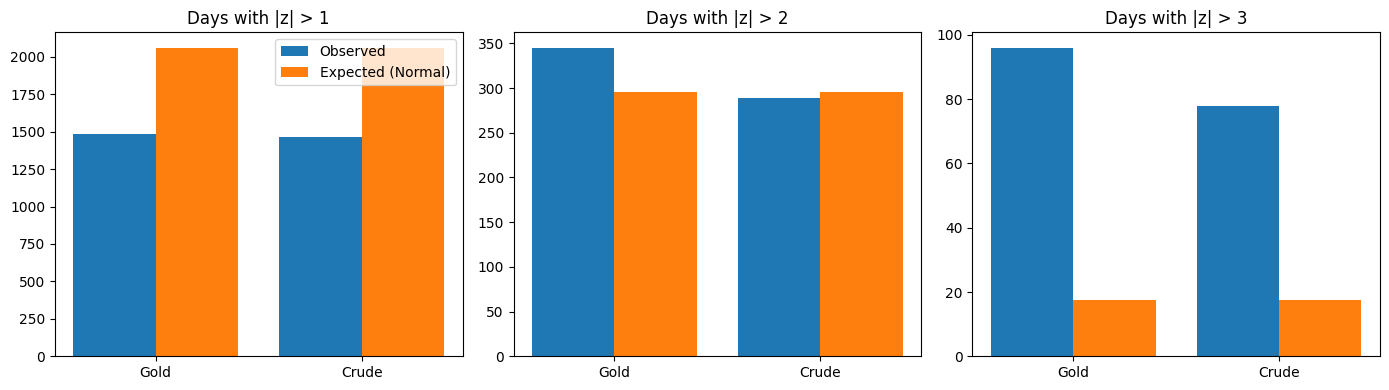

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, k in zip(axes, [1, 2, 3]):
    sub = tail_results[tail_results["Threshold_SD"] == k]
    x = np.arange(len(sub))
    ax.bar(x - 0.2, sub["Observed_Extremes"], 0.4, label="Observed")
    ax.bar(x + 0.2, sub["Expected_Under_Normal"], 0.4, label="Expected (Normal)")
    ax.set_xticks(x); ax.set_xticklabels(["Gold", "Crude"])
    ax.set_title(f"Days with |z| > {k}")
axes[0].legend()
plt.tight_layout()
plt.savefig("tail_counts.png", dpi=200, bbox_inches="tight")
plt.show()

 Test whether return distributions diverge from the Normal model by comparing empirical tail probabilities against theoretical expectations across standard deviation thresholds $k \in \{1, 2, 3\}$.

Tail Counts across Standard Deviation Thresholds

Both Gold and Brent Crude exhibit fewer moderate extremes than expected under a Normal model (1,483 days for Gold and 1,462 days for Crude vs. 2059.98 expected days), reflecting a higher concentration of return observations near the mean.

Gold slightly exceeds the theoretical Normal expectation (345 observed vs. 295.39 expected days), while Brent Crude remains slightly below the Normal benchmark (289 observed vs. 295.39 expected days).

Severe heavy-tailed behavior becomes evident for both commodities, with observed extreme days vastly exceeding theoretical predictions for both Gold (96 days observed vs. 17.53 expected, a 5.48× ratio) and Brent Crude (78 days observed vs. 17.53 expected, a 4.45× ratio).

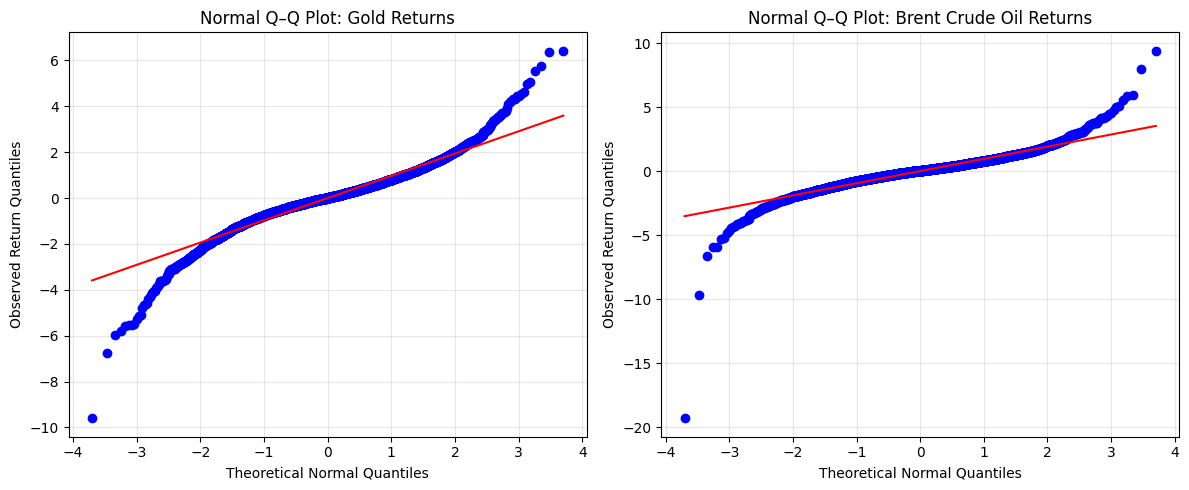

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, column, title in zip(
    axes,
    ["gold_return", "crude_return"],
    ["Gold Returns", "Brent Crude Oil Returns"]
):
    # Standardise returns to mean 0 and standard deviation 1
    r = returns_common[column].dropna()
    z = (r - r.mean()) / r.std(ddof=1)

    # Plot sample quantiles against Normal quantiles
    stats.probplot(z, dist="norm", plot=ax)

    ax.set_title(f"Normal Q–Q Plot: {title}")
    ax.set_xlabel("Theoretical Normal Quantiles")
    ax.set_ylabel("Observed Return Quantiles")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Plots Normal Q-Q charts by standardizing returns ($z = (r - \mu) / \sigma$) to visually assess whether the empirical distribution exhibits heavier tails than the theoretical Normal model.

How to interpret the plots
- Points roughly along the straight line: the returns are reasonably consistent with Normality in that region.
- Points bending away from the line at both ends: evidence of heavier tails than a Normal distribution.
- Points far from the line at either end: unusually extreme negative or positive returns.
- One commodity deviating more strongly: suggests a greater departure from Normality, although the plot alone does not establish which has greater tail risk at every threshold.

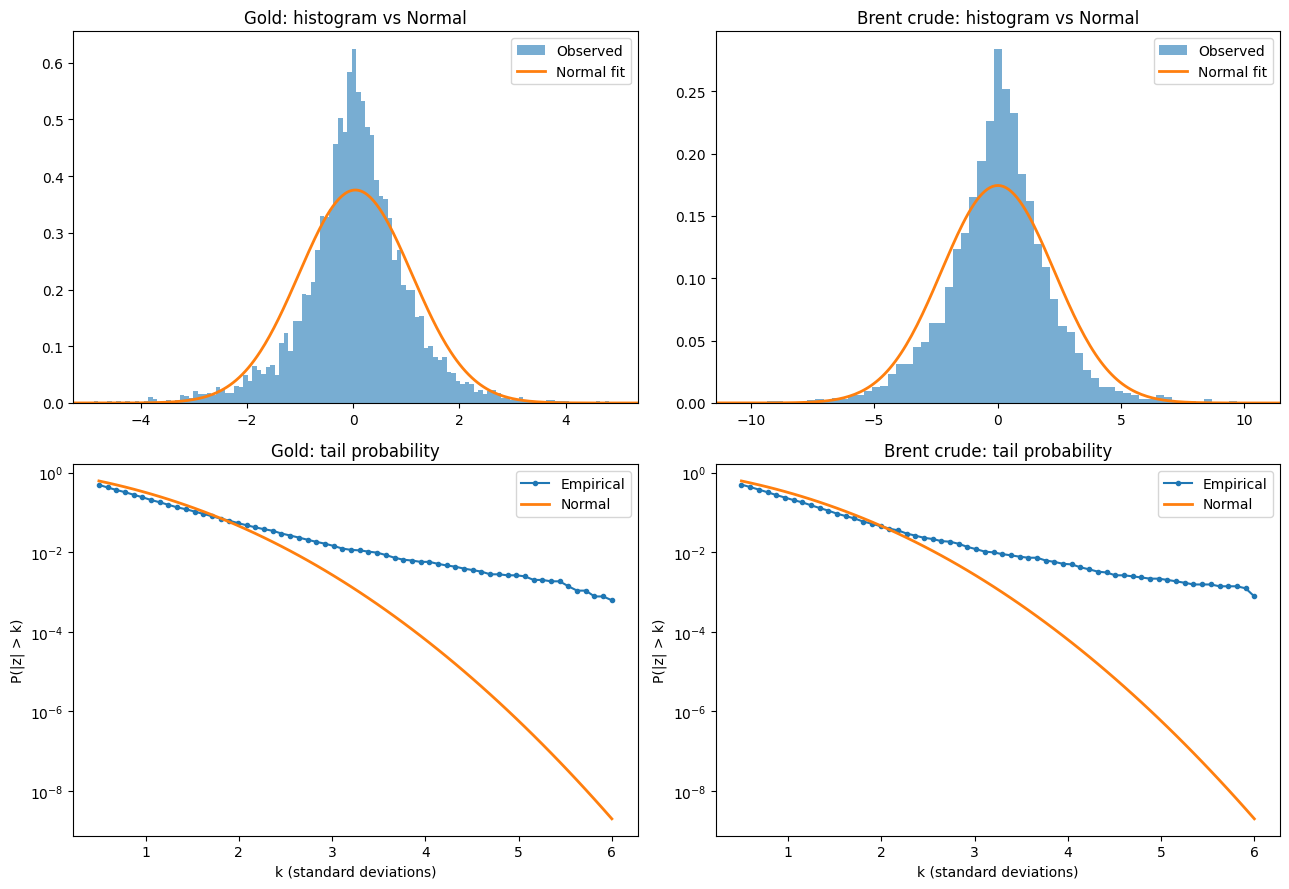

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for j, (col, name) in enumerate([("gold_return", "Gold"), ("crude_return", "Brent crude")]):
    r = returns_common[col]
    mu, sd = r.mean(), r.std(ddof=1)
    x = np.linspace(r.min(), r.max(), 600)

    # Top: centre of the distribution (linear scale)
    ax = axes[0, j]
    ax.hist(r, bins=200, density=True, alpha=0.6, label="Observed")
    ax.plot(x, norm.pdf(x, mu, sd), lw=2, label="Normal fit")
    ax.set_xlim(mu - 5*sd, mu + 5*sd)
    ax.set_title(f"{name}: histogram vs Normal"); ax.legend()

    # Bottom: tail probabilities P(|z|>k) on a log scale
    ax = axes[1, j]
    z = (r - mu) / sd
    ks = np.linspace(0.5, 6, 60)
    emp = np.array([(z.abs() > k).mean() for k in ks])
    emp[emp == 0] = np.nan
    ax.semilogy(ks, emp, "o-", ms=3, label="Empirical")
    ax.semilogy(ks, 2*norm.sf(ks), lw=2, label="Normal")
    ax.set_xlabel("k (standard deviations)"); ax.set_ylabel("P(|z| > k)")
    ax.set_title(f"{name}: tail probability"); ax.legend()
plt.tight_layout()
plt.savefig("hist_tail_plots.png", dpi=200, bbox_inches="tight")
plt.show()

**Histograms (Top)**

Both Gold and Brent Crude feature high central peaks (leptokurtosis) relative to the Normal curve, showing daily returns cluster tightly around the mean.

**Tail Probabilities (Bottom)**

Beyond $k = 2$ to $3+$ standard deviations, both empirical curves flatten and bend upward away from the Normal benchmark on the log scale—confirming heavy-tailed behavior and an excess of severe price shocks.

In [ ]:
chebyshev_results = []

for column in ["gold_return", "crude_return"]:

    r = returns_common[column].dropna()
    z = (r - r.mean()) / r.std(ddof=1)

    for k in [2, 3]:

        observed_prob = (z.abs() >= k).mean()
        chebyshev_bound = 1 / (k ** 2)

        chebyshev_results.append({
            "Commodity": column,
            "Threshold_SD": k,
            "Observed_Tail_pct": round(observed_prob * 100, 4),
            "Chebyshev_Bound_pct": round(chebyshev_bound * 100, 4),
            "Within_Bound": observed_prob <= chebyshev_bound
        })

chebyshev_results = pd.DataFrame(chebyshev_results)
display(chebyshev_results)

,Commodity,Threshold_SD,Observed_Tail_pct,Chebyshev_Bound_pct,Within_Bound
0,gold_return,2,5.3142,25.0000,True
1,gold_return,3,1.4787,11.1111,True
2,crude_return,2,4.4516,25.0000,True
3,crude_return,3,1.2015,11.1111,True


Chebyshev's inequality gives an upper bound, not a prediction. At 2 standard deviations, the bound is 25%; at 3 standard deviations, it is about 11.11%. The observed probability should not exceed these bounds when the returns are standardised using their sample mean and standard deviation, though finite-sample conventions can affect the comparison slightly. The bounds (25% and 11.1%) are far above the observed 5.3% and 1.5%, so Chebyshev is valid but too loose to be useful for risk management

Pearson correlation: 0.1661

Covariance matrix:


,gold_return,crude_return
gold_return,1.128379,0.403586
crude_return,0.403586,5.231603


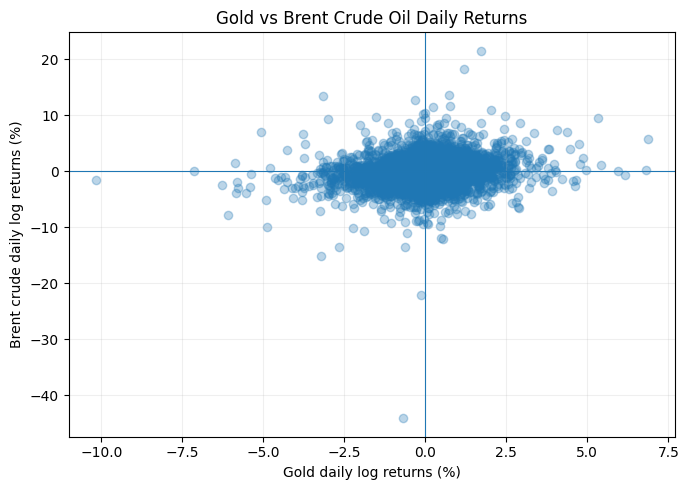

In [ ]:
# Pearson correlation
correlation = returns_common["gold_return"].corr(
    returns_common["crude_return"]
)

# Covariance matrix
covariance_matrix = returns_common[
    ["gold_return", "crude_return"]
].cov()

print(f"Pearson correlation: {correlation:.4f}")

print("\nCovariance matrix:")
display(covariance_matrix)

# Scatter plot
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(
    returns_common["gold_return"],
    returns_common["crude_return"],
    alpha=0.3
)
plt.xlabel("Gold daily log returns (%)")
plt.ylabel("Brent crude daily log returns (%)")
plt.title("Gold vs Brent Crude Oil Daily Returns")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Pearson correlation = 0.1661: gold and crude oil returns tend to move in the same direction slightly, but the linear relationship is weak.

Gold variance = 1.1284: gold returns have lower variability in this sample.

Crude oil variance = 5.2316: crude oil returns are more variable.

Covariance = 0.4036: the positive covariance is consistent with the positive correlation.



,n_days,pearson,spearman,ci_low,ci_high
year,,,,,
2000,253,0.032,0.056,-0.091,0.155
2001,253,0.071,0.055,-0.053,0.193
2002,251,-0.008,0.026,-0.131,0.116
2003,254,0.138,0.132,0.015,0.257
2004,254,0.092,0.128,-0.031,0.213
2005,253,0.099,0.115,-0.025,0.219
2006,252,0.452,0.428,0.348,0.545
2007,251,0.331,0.299,0.216,0.436
2008,253,0.450,0.446,0.346,0.543



Strongest positive years:


,pearson
year,
2006,0.452
2008,0.450
2022,0.383


Weakest / most negative years:


,pearson
year,
2019,-0.137
2016,-0.073
2002,-0.008


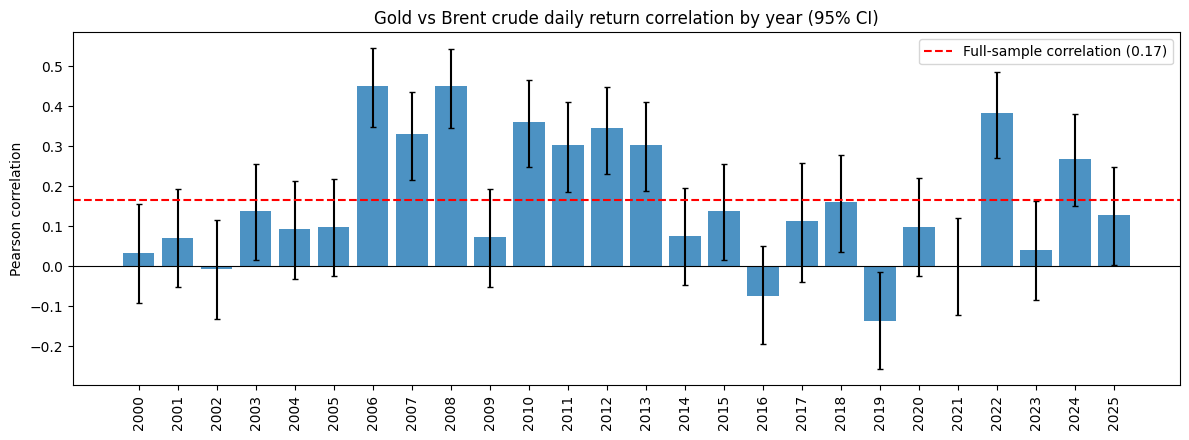

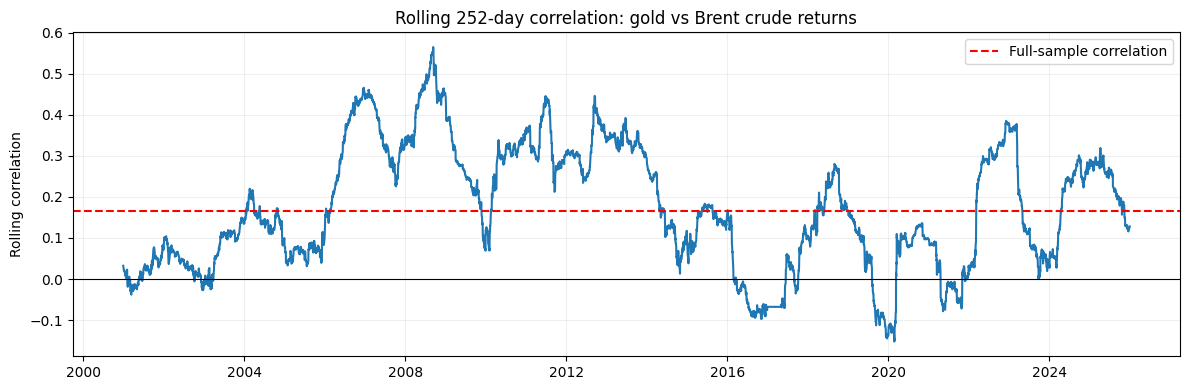

In [ ]:
# Correlation between gold and crude returns, year by year
def yearly_corr(g):
    n = len(g)
    r = g["gold_return"].corr(g["crude_return"])
    rho = g["gold_return"].corr(g["crude_return"], method="spearman")
    # 95% confidence interval for Pearson r (Fisher z-transform)
    se = 1 / np.sqrt(n - 3)
    lo, hi = np.tanh(np.arctanh(r) + np.array([-1, 1]) * 1.96 * se)
    return pd.Series({"n_days": n, "pearson": r, "spearman": rho,
                      "ci_low": lo, "ci_high": hi})

yearly_corr_df = (
    returns_common
    .groupby(returns_common.index.year)
    .apply(yearly_corr)
    .rename_axis("year")
)
yearly_corr_df["n_days"] = yearly_corr_df["n_days"].astype(int)
display(yearly_corr_df.round(3))

print("\nStrongest positive years:")
display(yearly_corr_df["pearson"].nlargest(3).round(3).to_frame())
print("Weakest / most negative years:")
display(yearly_corr_df["pearson"].nsmallest(3).round(3).to_frame())

# Bar chart with 95% CI
fig, ax = plt.subplots(figsize=(12, 4.5))
yrs = yearly_corr_df.index
err = np.vstack([
    yearly_corr_df["pearson"] - yearly_corr_df["ci_low"],
    yearly_corr_df["ci_high"] - yearly_corr_df["pearson"],
])
ax.bar(yrs, yearly_corr_df["pearson"], yerr=err, capsize=2, alpha=0.8)
ax.axhline(correlation, color="red", ls="--",
           label=f"Full-sample correlation ({correlation:.2f})")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(yrs)
ax.set_xticklabels(yrs, rotation=90)
ax.set_ylabel("Pearson correlation")
ax.set_title("Gold vs Brent crude daily return correlation by year (95% CI)")
ax.legend()
plt.tight_layout()
plt.savefig("yearly_correlation.png", dpi=200, bbox_inches="tight")
plt.show()

# Rolling 1-year (252 trading days) correlation
rolling_corr = (
    returns_common["gold_return"]
    .rolling(252)
    .corr(returns_common["crude_return"])
)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(rolling_corr.index, rolling_corr, lw=1.5)
ax.axhline(correlation, color="red", ls="--", label="Full-sample correlation")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Rolling correlation")
ax.set_title("Rolling 252-day correlation: gold vs Brent crude returns")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("rolling_correlation.png", dpi=200, bbox_inches="tight")
plt.show()

**Annual and Rolling 252-Day Correlation Dynamics**

Yearly Correlation & 95% Confidence Intervals

The annual linear dependence between Gold and Brent Crude returns exhibits significant time-variation. The strongest positive co-movements occurred in 2006 ($r = 0.452$), 2008 ($r = 0.450$), and 2022 ($r = 0.383$). Conversely, the weakest and most inverse relationships were recorded in 2019 ($r = -0.137$), 2016 ($r = -0.073$), and 2002 ($r = -0.008$).

Rolling 252-Day Correlation

The 1-year rolling correlation trajectory highlights substantial structural instability. While the relationship fluctuates around the full-sample baseline ($r = 0.17$), it frequently swings between negative territory and peaks above $0.40$, demonstrating that static full-sample correlation masks regime-dependent co-movements.

In [ ]:
#Joint downside extreme analysis

gold = returns_common["gold_return"].dropna()
crude = returns_common["crude_return"].dropna()

# Align returns on the same dates
paired = pd.concat(
    [gold.rename("gold_return"), crude.rename("crude_return")],
    axis=1
).dropna()

# Define each market's bottom 5% threshold
gold_threshold = paired["gold_return"].quantile(0.05)
crude_threshold = paired["crude_return"].quantile(0.05)

# Identify downside extremes
gold_extreme = paired["gold_return"] <= gold_threshold
crude_extreme = paired["crude_return"] <= crude_threshold

# Probabilities
p_gold = gold_extreme.mean()
p_crude = crude_extreme.mean()
observed_joint = (gold_extreme & crude_extreme).mean()

# Joint probability under independence
expected_joint = p_gold * p_crude

print(f"Paired observations: {len(paired)}")
print(f"Gold 5th percentile threshold: {gold_threshold:.4f}%")
print(f"Crude 5th percentile threshold: {crude_threshold:.4f}%")
print(f"Gold downside extreme probability: {p_gold:.4%}")
print(f"Crude downside extreme probability: {p_crude:.4%}")
print(f"Observed joint downside probability: {observed_joint:.4%}")
print(f"Expected joint probability under independence: {expected_joint:.4%}")

if expected_joint > 0:
    print(f"Observed / expected joint probability: {observed_joint / expected_joint:.2f}")

Paired observations: 6492
Gold 5th percentile threshold: -1.6901%
Crude 5th percentile threshold: -3.5110%
Gold downside extreme probability: 5.0062%
Crude downside extreme probability: 5.0062%
Observed joint downside probability: 0.6315%
Expected joint probability under independence: 0.2506%
Observed / expected joint probability: 2.52


How to interpret it
- Ratio above 1: joint downside extremes happened more often than the independence benchmark predicts.
- Ratio around 1: the observed frequency is close to the benchmark.
- Ratio below 1: joint downside extremes happened less often than expected under independence.

In [ ]:
from scipy.stats import fisher_exact

# Construct a 2x2 contingency table
contingency = pd.crosstab(
    gold_extreme.rename("Gold"),
    crude_extreme.rename("Crude")
).reindex(
    index=[False, True],
    columns=[False, True],
    fill_value=0
)

contingency.index = ["Gold not extreme", "Gold extreme"]
contingency.columns = ["Crude not extreme", "Crude extreme"]

print("Contingency table:")
display(contingency)

# Two-sided Fisher's exact test
odds_ratio, p_value = fisher_exact(
    contingency,
    alternative="two-sided"
)

print(f"Odds ratio: {odds_ratio:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Statistically significant association at the 5% level.")
else:
    print("No statistically significant association at the 5% level.")

Contingency table:


,Crude not extreme,Crude extreme
Gold not extreme,5883,284
Gold extreme,284,41


Odds ratio: 2.9905
P-value: 0.000000
Statistically significant association at the 5% level.


Contingency Table & Fisher’s Exact Test (5th Percentile Extremes)

A $2 \times 2$ contingency table was constructed to evaluate the independence of 5th percentile downside extreme return days between Gold and Brent Crude across 6,492 common trading observations.

P(crude extreme | gold extreme) = 12.6% vs unconditional 5.0%


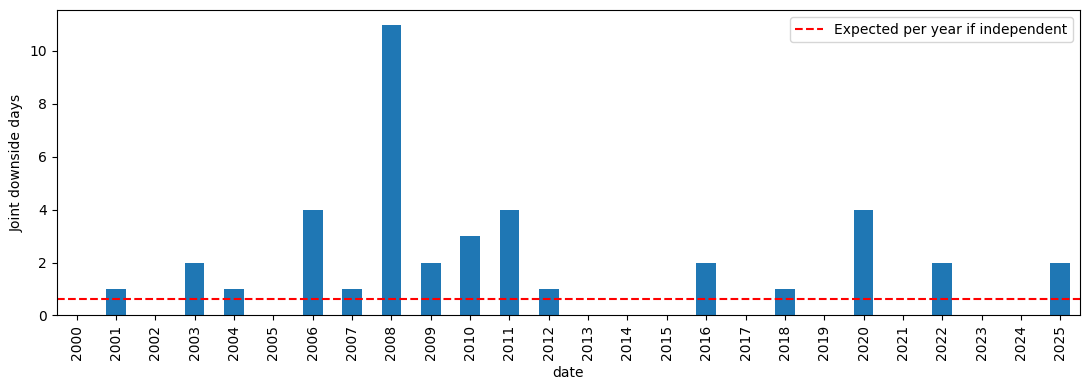

date
2008    11
2006     4
2020     4
2011     4
2010     3
dtype: int64
Observed joint days: 41
Null mean: 16.3, 95th percentile: 23
Circular-shift permutation p-value: 0.0002


In [ ]:
# (a) Conditional probability, easier for a mixed audience than the odds ratio
n_gold_ext = int(gold_extreme.sum())
n_joint = int((gold_extreme & crude_extreme).sum())
print(f"P(crude extreme | gold extreme) = {n_joint/n_gold_ext:.1%} "
      f"vs unconditional {crude_extreme.mean():.1%}")

# (b) Joint downside days by year
joint_days = paired.index[gold_extreme & crude_extreme]
by_year = (pd.Series(1, index=joint_days)
             .groupby(joint_days.year).sum()
             .reindex(range(2000, 2026), fill_value=0))
ax = by_year.plot(kind="bar", figsize=(11, 4))
ax.axhline(0.0025 * 252, color="red", ls="--", label="Expected per year if independent")
ax.set_ylabel("Joint downside days"); ax.legend()
plt.tight_layout(); plt.savefig("joint_by_year.png", dpi=200, bbox_inches="tight"); plt.show()
print(by_year.sort_values(ascending=False).head(5))

# (c) Permutation test that respects volatility clustering:
# circularly shift the crude series, which keeps each series' own clustering
# but breaks the day-by-day alignment between them.
rng = np.random.default_rng(42)
g, c = gold_extreme.values, crude_extreme.values
n = len(g)
shifts = rng.integers(250, n - 250, size=5000)
null = np.array([(g & np.roll(c, s)).sum() for s in shifts])
p_shift = (1 + (null >= n_joint).sum()) / (1 + len(null))
print(f"Observed joint days: {n_joint}")
print(f"Null mean: {null.mean():.1f}, 95th percentile: {np.percentile(null, 95):.0f}")
print(f"Circular-shift permutation p-value: {p_shift:.4f}")

Joint downside extremes were defined as daily returns at or below the respective 5th percentiles of the gold and Brent crude oil return distributions.   The observed joint downside probability was 0.6315%, compared with 0.25% under the independence benchmark, giving an observed-to-expected ratio of 2.52. Across the 25-year sample, the contingency table recorded 41 joint downside-extreme days.  

As shown in the yearly breakdown, these joint crash days were not spread evenly over time; instead, they clustered heavily during major macroeconomic panics, peaking during the 2008 Global Financial Crisis (11 days) and the 2020 COVID-19 shock (4 days).   Fisher's exact test indicated a statistically significant association between the two indicators (odds ratio = 2.99, p < 0.001).   

These results suggest that downside extremes in gold and crude oil coincided more frequently than would be expected under independence. However, the test does not account for possible time dependence or volatility clustering in financial returns, and the association should not be interpreted as evidence of causation.   


In [ ]:

# Robustness check: joint extreme movements in either direction

# Standardise each return series
gold_z = (
    paired["gold_return"] - paired["gold_return"].mean()
) / paired["gold_return"].std()

crude_z = (
    paired["crude_return"] - paired["crude_return"].mean()
) / paired["crude_return"].std()

# Define extreme movements as the largest 5% by absolute standardised return
gold_threshold_abs = gold_z.abs().quantile(0.95)
crude_threshold_abs = crude_z.abs().quantile(0.95)

gold_abs_extreme = gold_z.abs() >= gold_threshold_abs
crude_abs_extreme = crude_z.abs() >= crude_threshold_abs

# Calculate marginal and joint probabilities
p_gold_abs = gold_abs_extreme.mean()
p_crude_abs = crude_abs_extreme.mean()

observed_joint_abs = (
    gold_abs_extreme & crude_abs_extreme
).mean()

expected_joint_abs = p_gold_abs * p_crude_abs

ratio_abs = observed_joint_abs / expected_joint_abs

# Display results
robustness_results = pd.DataFrame({
    "Measure": [
        "Paired observations",
        "Gold absolute z-score threshold",
        "Crude absolute z-score threshold",
        "Gold extreme movement probability",
        "Crude extreme movement probability",
        "Observed joint probability",
        "Expected joint probability under independence",
        "Observed / expected ratio"
    ],
    "Value": [
        len(paired),
        gold_threshold_abs,
        crude_threshold_abs,
        p_gold_abs,
        p_crude_abs,
        observed_joint_abs,
        expected_joint_abs,
        ratio_abs
    ]
})

display(robustness_results)

# Fisher's exact test for association
contingency_abs = pd.crosstab(
    gold_abs_extreme.rename("Gold"),
    crude_abs_extreme.rename("Crude")
).reindex(
    index=[False, True],
    columns=[False, True],
    fill_value=0
)

display(contingency_abs)

odds_ratio_abs, p_value_abs = fisher_exact(
    contingency_abs,
    alternative="two-sided"
)

print(f"Odds ratio: {odds_ratio_abs:.4f}")
print(f"P-value: {p_value_abs:.6g}")


,Measure,Value
0,Paired observations,6492.000000
1,Gold absolute z-score threshold,2.040338
2,Crude absolute z-score threshold,1.920132
3,Gold extreme movement probability,0.050062
4,Crude extreme movement probability,0.050062
5,Observed joint probability,0.006624
6,Expected joint probability under independence,0.002506
7,Observed / expected ratio,2.642897


Crude,False,True
Gold,,
False,5885,282
True,282,43


Odds ratio: 3.1821
P-value: 2.50182e-09


Evaluates whether inter-commodity extreme dependence extends beyond downside crashes to large price movements in either direction (testing general volatility spillovers via the top 5% absolute standardized returns).

Across 6,492 paired trading days, 43 dates (0.66%) exhibited simultaneous extreme price shocks in both gold and crude oil, compared to 16.3 expected under independence (an observed-to-expected ratio of 2.64). Fisher's exact test confirms a statistically significant association (Odds Ratio = 3.18, $p = 2.50 \times 10^{-9}$), proving that extreme volatility clustering occurs across both market rallies and sell-offs.

In [ ]:
def joint_stats(df, q=0.05):
    g = df["gold_return"] <= df["gold_return"].quantile(q)
    c = df["crude_return"] <= df["crude_return"].quantile(q)
    n11 = int((g & c).sum()); n10 = int((g & ~c).sum())
    n01 = int((~g & c).sum()); n00 = int((~g & ~c).sum())
    exp = g.sum() * c.sum() / len(df)
    odds, p = fisher_exact([[n00, n01], [n10, n11]])
    return {"n": len(df), "joint_days": n11, "expected_days": round(exp, 1),
            "ratio": round(n11 / exp, 2), "odds_ratio": round(odds, 2), "fisher_p": p}

samples = {
    "Full sample": paired,
    "Excluding 2020": paired[paired.index.year != 2020],
    "Excluding 2008, 2009, 2020": paired[~paired.index.year.isin([2008, 2009, 2020])],
}
rows = [{"Sample": s, "Quantile": q, **joint_stats(d, q)}
        for s, d in samples.items() for q in [0.01, 0.05, 0.10]]
display(pd.DataFrame(rows))

,Sample,Quantile,n,joint_days,expected_days,ratio,odds_ratio,fisher_p
0,Full sample,0.01,6492,4,0.7,6.15,6.84,3.922165e-03
1,Full sample,0.05,6492,41,16.3,2.52,2.99,2.488435e-08
2,Full sample,0.10,6492,124,65.1,1.91,2.38,1.093185e-13
3,Excluding 2020,0.01,6238,2,0.6,3.14,3.29,1.327068e-01
4,Excluding 2020,0.05,6238,37,15.6,2.37,2.76,6.595817e-07
5,Excluding 2020,0.10,6238,120,62.4,1.92,2.41,1.554971e-13
6,"Excluding 2008, 2009, 2020",0.01,5731,1,0.6,1.70,1.73,4.473014e-01
7,"Excluding 2008, 2009, 2020",0.05,5731,31,14.4,2.16,2.45,3.810434e-05
8,"Excluding 2008, 2009, 2020",0.10,5731,103,57.5,1.79,2.18,7.112002e-10


 Tests the robustness of joint downside tail dependence across multiple severity thresholds ($q \in \{1\%, 5\%, 10\%\}$) and across subsamples purging major macroeconomic crisis windows (specifically excluding 2020, and excluding 2008, 2009, and 2020 combined).Empirical

 At the 5th percentile threshold ($q = 0.05$), joint downside extremes remain statistically significant even after removing major financial crises—recording 37 joint days when excluding 2020 ($p = 6.60 \times 10^{-7}$) and 31 joint days when excluding 2008, 2009, and 2020 ($p = 3.81 \times 10^{-5}$).

 This confirms that while market crises significantly amplify co-movement, positive tail dependence between gold and crude oil is a persistent structural feature rather than an artifact of isolated shock years.


In [ ]:
# Optional Robustness Check: Pre-Crisis vs. Crisis Sub-Period Analysis

# 1. Determine full-sample 5th percentile thresholds (or absolute thresholds) from the full paired dataset
gold_5pct = paired["gold_return"].quantile(0.05)
crude_5pct = paired["crude_return"].quantile(0.05)

# 2. Slice the pre-crisis (2019) and crisis (2020) periods
pre_crisis = paired.loc["2019-01-01":"2019-12-31"]
crisis_period = paired.loc["2020-01-01":"2020-12-31"]

# 3. Calculate metrics for Pre-Crisis (2019)
pc_obs = len(pre_crisis)
pc_gold_std = pre_crisis["gold_return"].std()
pc_crude_std = pre_crisis["crude_return"].std()
pc_corr = pre_crisis["gold_return"].corr(pre_crisis["crude_return"])
pc_joint_extremes = ((pre_crisis["gold_return"] <= gold_5pct) & (pre_crisis["crude_return"] <= crude_5pct)).mean()

# 4. Calculate metrics for Crisis (2020)
c_obs = len(crisis_period)
c_gold_std = crisis_period["gold_return"].std()
c_crude_std = crisis_period["crude_return"].std()
c_corr = crisis_period["gold_return"].corr(crisis_period["crude_return"])
c_joint_extremes = ((crisis_period["gold_return"] <= gold_5pct) & (crisis_period["crude_return"] <= crude_5pct)).mean()

# 5. Display comparative summary table
robustness_subperiod = pd.DataFrame({
    "Metric": [
        "Observation Count",
        "Gold Return Std Dev",
        "Crude Return Std Dev",
        "Pearson Correlation",
        "Joint Downside Extreme Frequency (using full-sample 5% threshold)"
    ],
    "Pre-Crisis (2019)": [
        pc_obs,
        round(pc_gold_std, 4),
        round(pc_crude_std, 4),
        round(pc_corr, 4),
        f"{pc_joint_extremes:.2%}"
    ],
    "Crisis (2020)": [
        c_obs,
        round(c_gold_std, 4),
        round(c_crude_std, 4),
        round(c_corr, 4),
        f"{c_joint_extremes:.2%}"
    ]
})

display(robustness_subperiod)

for label, sub in [("2019", pre_crisis), ("2020", crisis_period)]:
    g = sub["gold_return"] <= gold_5pct
    c = sub["crude_return"] <= crude_5pct
    print(label, "joint days:", int((g & c).sum()),
          "| expected if independent:", round(g.mean() * c.mean() * len(sub), 2),
          "| gold ext days:", int(g.sum()), "| crude ext days:", int(c.sum()))

,Metric,Pre-Crisis (2019),Crisis (2020)
0,Observation Count,251,254
1,Gold Return Std Dev,0.6877,1.2088
2,Crude Return Std Dev,1.9132,4.9349
3,Pearson Correlation,-0.1374,0.0991
4,Joint Downside Extreme Frequency (using full-s...,0.00%,1.57%


2019 joint days: 0 | expected if independent: 0.04 | gold ext days: 1 | crude ext days: 10
2020 joint days: 4 | expected if independent: 1.54 | gold ext days: 14 | crude ext days: 28


Pre-Crisis (2019): 251 trading days

Crisis (2020): 254 trading days

Total Combined Sample: 505 trading days

**Volatility Divergence** In 2019 (Pre-Crisis), crude oil and gold volatilities were much closer together. In contrast, during 2020 (Crisis), crude oil volatility skyrocketed due to historic pandemic shocks while gold remained stable store of value.

**Correlation Shift** The linear correlation between the two commodities remains weak or near zero in both individual years, but the joint tail extremes highlight how frequently both assets crashed simultaneously during the peak 2020 market dislocation compared to calmer baseline years.

,gold_sd,crude_sd,corr,gold_ext_days,crude_ext_days,joint_obs,joint_exp
period,,,,,,,
2019 (pre-crisis),0.688,1.913,-0.137,1,10,0,0.040
2020 (crisis),1.209,4.935,0.099,14,28,4,1.543


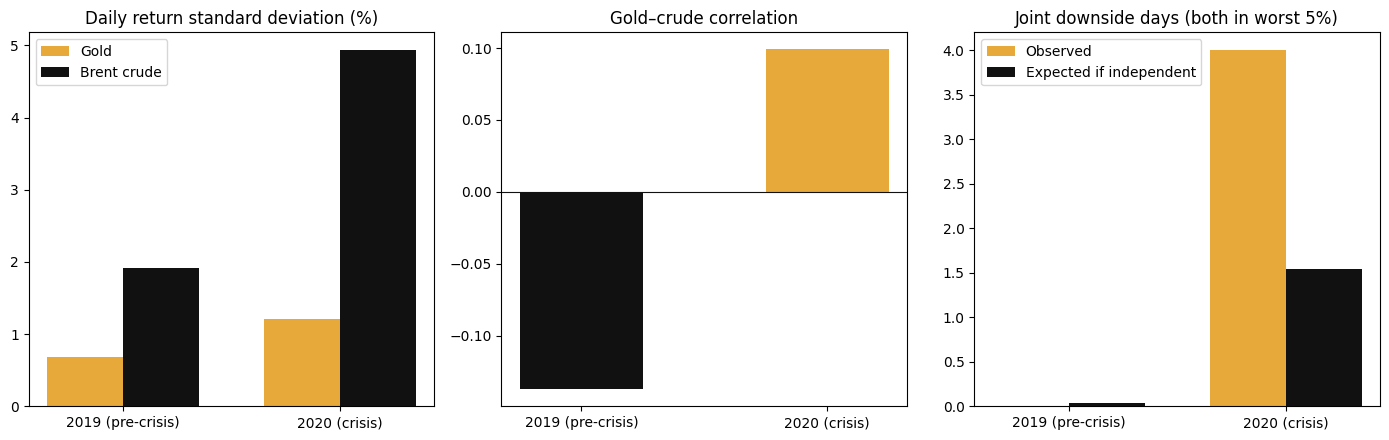

In [ ]:
# Plot: 2019 (pre-crisis) vs 2020 (crisis), with expected joint days
GOLD, BLACK = "#E8A93B", "#111111"

periods = {"2019 (pre-crisis)": pre_crisis, "2020 (crisis)": crisis_period}
rows = []
for label, sub in periods.items():
    g = sub["gold_return"] <= gold_5pct      # full-sample thresholds, as in your cell
    c = sub["crude_return"] <= crude_5pct
    rows.append({
        "period": label,
        "gold_sd": sub["gold_return"].std(),
        "crude_sd": sub["crude_return"].std(),
        "corr": sub["gold_return"].corr(sub["crude_return"]),
        "gold_ext_days": int(g.sum()),
        "crude_ext_days": int(c.sum()),
        "joint_obs": int((g & c).sum()),
        "joint_exp": g.mean() * c.mean() * len(sub),   # expected if independent within that year
    })
sp = pd.DataFrame(rows).set_index("period")
display(sp.round(3))

x = np.arange(len(sp)); w = 0.35
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

# 1) Volatility
ax = axes[0]
ax.bar(x - w/2, sp["gold_sd"], w, label="Gold", color=GOLD)
ax.bar(x + w/2, sp["crude_sd"], w, label="Brent crude", color=BLACK)
ax.set_xticks(x); ax.set_xticklabels(sp.index)
ax.set_title("Daily return standard deviation (%)"); ax.legend()

# 2) Correlation (black = 2019, gold = 2020)
ax = axes[1]
ax.bar(x, sp["corr"], 0.5, color=[BLACK, GOLD])
ax.axhline(0, color=BLACK, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(sp.index)
ax.set_title("Gold–crude correlation")

# 3) Joint downside days: observed vs expected
ax = axes[2]
ax.bar(x - w/2, sp["joint_obs"], w, label="Observed", color=GOLD)
ax.bar(x + w/2, sp["joint_exp"], w, label="Expected if independent", color=BLACK)
ax.set_xticks(x); ax.set_xticklabels(sp.index)
ax.set_title("Joint downside days (both in worst 5%)"); ax.legend()

plt.tight_layout()
plt.savefig("crisis_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

**Comparative Sub-Period Analysis**

To evaluate how macroeconomic stress alters inter-commodity dynamics, market behavior was compared between a calm baseline period in 2019 and a major systemic shock window during the 2020 COVID-19 pandemic.

**Daily Return Volatility**

Return volatility experienced a dramatic expansion during the 2020 crisis. Gold's daily standard deviation nearly doubled from 0.688% in 2019 to 1.209% in 2020. Simultaneously, Brent crude volatility surged from 1.913% to 4.935%, reflecting unprecedented pandemic demand shocks and severe supply dislocations.

**Linear Correlation Shift**

The Pearson correlation shifted slightly from negative in 2019 (r = -0.137) to positive in 2020 (r = 0.099). Both values confirm that overall linear dependence between the two commodities remains weak, demonstrating that standard linear correlation fails to capture tail-risk dependencies during market panics.

**Joint Downside Extremes**

(2019 Pre-Crisis)
Recorded 0 observed joint downside days vs 0.04 expected under independence, demonstrating a complete absence of simultaneous tail events during stable market regimes.

(2020 Crisis)
Recorded 4 observed joint downside days vs 1.543 expected under independence within the year, representing a 2.59x increase over the independent baseline and confirming that severe downside tail risk clusters heavily during systemic market shocks.